# 03 - Technical Feature Engineering & Target Formulation
## Machine Learning Lab Project: Cryptocurrency Price Forecasting

### 🎯 Objective
Transform raw OHLCV prices into informative quantitative signals:
1. **Trend & Moving Averages:** Simple Moving Average (`SMA_7`, `SMA_21`), Exponential Moving Average (`EMA_14`), Moving Average Ratio.
2. **Momentum:** Relative Strength Index (`RSI_14`), Moving Average Convergence Divergence (`MACD`, `MACD Signal`, `MACD Histogram`).
3. **Volatility:** Bollinger Bands (`Upper`, `Lower`, `Width`), Average True Range (`ATR_14`), Rolling Return Volatility.
4. **Volume & Liquidity:** Volume moving average ratio, High-Low spread ratio.
5. **Target Formulation:** Next-candle close price ($P_{t+1}$) for regression, and future return direction (Binary Up/Down).

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('..'))
import src

# Load raw 1h data as demonstration
df_raw = src.load_timeframe_data('1h', data_dir='../data/raw')
print(f"Raw 1h rows: {len(df_raw)}")

Raw 1h rows: 800


### ⚙️ Extracting Quantitative Indicators
We execute the feature extraction pipeline from `src.features`.

In [2]:
df_features = src.engineer_features(df_raw)
print(f"Feature matrix shape after dropping NaNs: {df_features.shape}")
print("\nGenerated Features:")
print(src.FEATURE_COLUMNS)
df_features[src.FEATURE_COLUMNS[:10]].head()

Feature matrix shape after dropping NaNs: (779, 30)

Generated Features:
['open', 'high', 'low', 'close', 'volume', 'return_1', 'return_3', 'return_5', 'log_return', 'sma_7', 'sma_21', 'ema_14', 'ma_ratio', 'macd', 'macd_signal', 'macd_hist', 'bb_width', 'volatility_14', 'atr_14', 'vol_ratio', 'hl_spread', 'rsi_14']


,open,high,low,close,volume,return_1,return_3,return_5,log_return,sma_7
0,77604.01,77850.00,77566.11,77798.01,1203.27789,0.002500,0.002862,0.010517,0.002497,77369.651429
1,77798.00,78279.80,77660.00,78272.15,1082.03924,0.006095,0.010044,0.011484,0.006076,77587.957143
2,78271.48,78490.79,77961.57,78212.01,1198.98878,-0.000768,0.007835,0.008199,-0.000769,77762.772857
3,78212.00,78369.86,78102.00,78285.34,396.04476,0.000938,0.006264,0.010214,0.000937,77891.611429
4,78285.35,78450.01,78026.00,78062.00,564.41098,-0.002853,-0.002685,0.005902,-0.002857,77961.044286


### 📈 Visualizing Technical Indicators (RSI, MACD, Bollinger Bands)

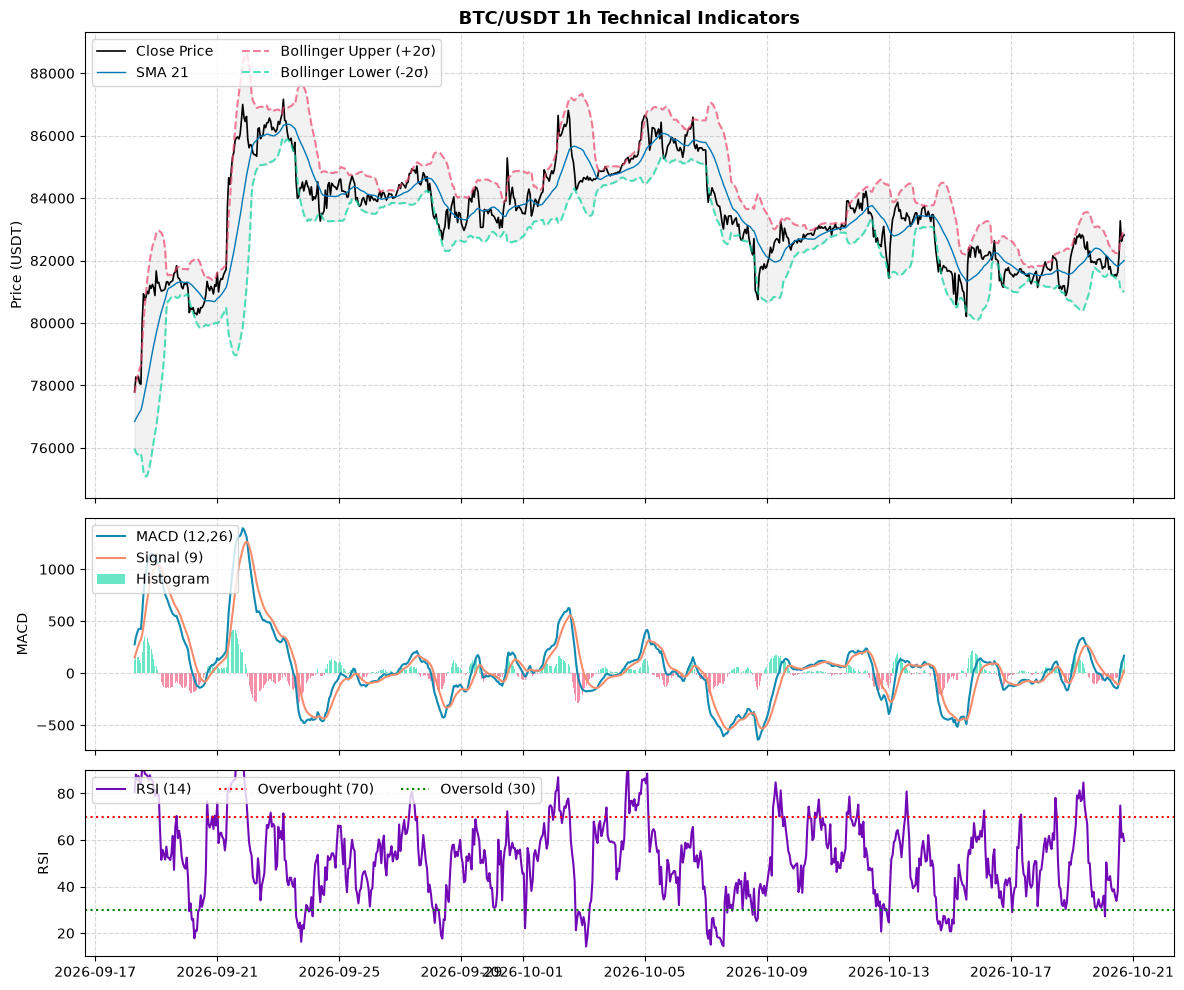

In [3]:
fig, (ax_price, ax_macd, ax_rsi) = plt.subplots(3, 1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1.5, 1.2]})

# Price & Bollinger Bands
ax_price.plot(df_features['timestamp'], df_features['close'], label='Close Price', color='black', lw=1.2)
ax_price.plot(df_features['timestamp'], df_features['sma_21'], label='SMA 21', color='#0077b6', lw=1.0)
ax_price.plot(df_features['timestamp'], df_features['bb_upper'], '--', color='#ef476f', alpha=0.7, label='Bollinger Upper (+2σ)')
ax_price.plot(df_features['timestamp'], df_features['bb_lower'], '--', color='#06d6a0', alpha=0.7, label='Bollinger Lower (-2σ)')
ax_price.fill_between(df_features['timestamp'], df_features['bb_lower'], df_features['bb_upper'], color='gray', alpha=0.1)
ax_price.set_title('BTC/USDT 1h Technical Indicators', fontsize=13, fontweight='bold')
ax_price.set_ylabel('Price (USDT)')
ax_price.legend(loc='upper left', ncol=2)
ax_price.grid(True, linestyle='--', alpha=0.5)

# MACD
ax_macd.plot(df_features['timestamp'], df_features['macd'], label='MACD (12,26)', color='#118ab2')
ax_macd.plot(df_features['timestamp'], df_features['macd_signal'], label='Signal (9)', color='#f78c6b')
ax_macd.bar(df_features['timestamp'], df_features['macd_hist'], width=0.03, color=np.where(df_features['macd_hist']>0, '#06d6a0', '#ef476f'), alpha=0.6, label='Histogram')
ax_macd.set_ylabel('MACD')
ax_macd.legend(loc='upper left')
ax_macd.grid(True, linestyle='--', alpha=0.5)

# RSI
ax_rsi.plot(df_features['timestamp'], df_features['rsi_14'], label='RSI (14)', color='#7209b7')
ax_rsi.axhline(70, color='r', linestyle=':', label='Overbought (70)')
ax_rsi.axhline(30, color='g', linestyle=':', label='Oversold (30)')
ax_rsi.set_ylim(10, 90)
ax_rsi.set_ylabel('RSI')
ax_rsi.legend(loc='upper left', ncol=3)
ax_rsi.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 🔗 Feature Correlation with Next-Candle Target Price

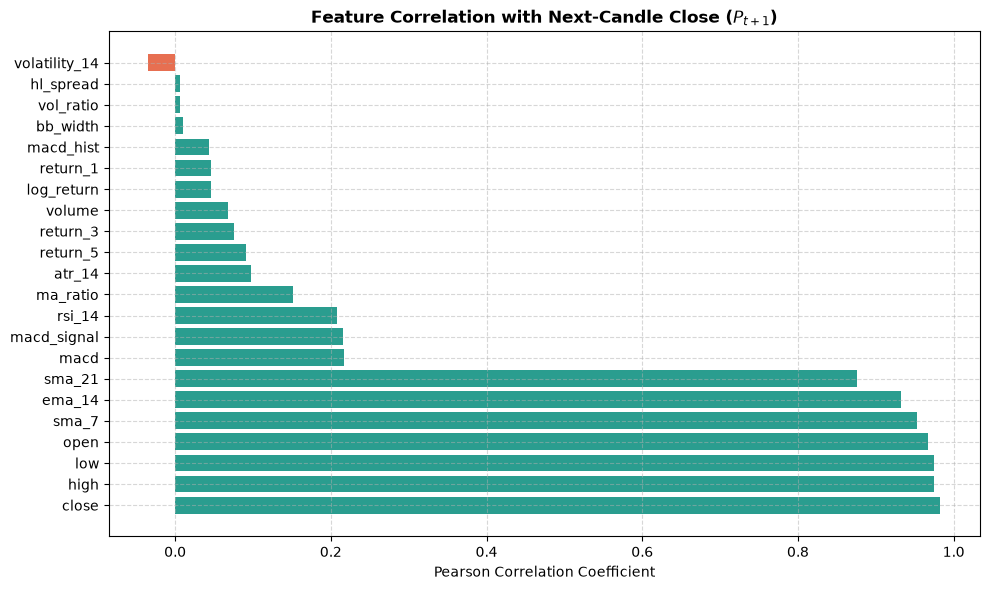

In [4]:
corr_series = df_features[src.FEATURE_COLUMNS].apply(lambda col: col.corr(df_features['target_next_close']))
corr_df = corr_series.sort_values(ascending=False).to_frame(name='Correlation_with_Next_Close')

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#2a9d8f' if v > 0 else '#e76f51' for v in corr_df['Correlation_with_Next_Close']]
ax.barh(corr_df.index, corr_df['Correlation_with_Next_Close'], color=colors)
ax.set_title('Feature Correlation with Next-Candle Close ($P_{t+1}$)', fontsize=12, fontweight='bold')
ax.set_xlabel('Pearson Correlation Coefficient')
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 💾 Processing and Storing Features Across All 13 Timeframes

In [5]:
os.makedirs('../data/processed', exist_ok=True)
processed_summary = []

for tf in src.DEFAULT_TIMEFRAMES:
    try:
        raw_df = src.load_timeframe_data(tf, data_dir='../data/raw')
        feat_df = src.engineer_features(raw_df)
        save_path = os.path.join('../data/processed', f'BTC_USDT_{tf}_features.csv')
        feat_df.to_csv(save_path, index=False)
        processed_summary.append({
            'Timeframe': tf,
            'Feature_Rows': len(feat_df),
            'Feature_Count': len(src.FEATURE_COLUMNS),
            'Processed_File': save_path
        })
    except Exception as e:
        print(f"Error processing {tf}: {e}")

pd.DataFrame(processed_summary)

,Timeframe,Feature_Rows,Feature_Count,Processed_File
0,1m,779,22,../data/processed/BTC_USDT_1m_features.csv
1,3m,779,22,../data/processed/BTC_USDT_3m_features.csv
2,5m,779,22,../data/processed/BTC_USDT_5m_features.csv
3,10m,379,22,../data/processed/BTC_USDT_10m_features.csv
4,15m,779,22,../data/processed/BTC_USDT_15m_features.csv
5,30m,779,22,../data/processed/BTC_USDT_30m_features.csv
6,1h,779,22,../data/processed/BTC_USDT_1h_features.csv
7,2h,779,22,../data/processed/BTC_USDT_2h_features.csv
8,4h,779,22,../data/processed/BTC_USDT_4h_features.csv
9,12h,779,22,../data/processed/BTC_USDT_12h_features.csv


### 📝 Lab Summary
- Extracted 22 financial engineering signals covering momentum, trend, volatility, and volume.
- Created future target close $P_{t+1}$ shifted by $-1$, ensuring clean temporal integrity without future data leakage.
- Saved standardized feature matrices for all 13 timeframes in `data/processed/`.